# Unrolled RDBM 4× reconstruction

This notebook reviews the **50-epoch / 94,900-step** supervised experiment trained
from random initialization. The model shares one RDBM-derived denoiser across three
cascades and applies a six-iteration conjugate-gradient SENSE consistency solve after
each cascade. Epochs 10, 20, 30, 40, and 50 were screened on validation data; the
selected checkpoint was then evaluated on the held-out test set.

In [1]:
from pathlib import Path
from html import escape
import json, re
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RUN = Path('/data/david_agyei/nyu-dataset/derived/unrolled_rdbm_4x_scratch')
EVAL = RUN / 'evaluation'
RDBM_EVAL = Path('/data/david_agyei/nyu-dataset/derived/rdbm_full_bf16/evaluation')

def read_json(path): return json.loads(Path(path).read_text())
def show_table(rows, columns, precision=4, bold_best=None):
    bold_best = bold_best or {}
    best = {}
    for key, direction in bold_best.items():
        values = [row[key] for row in rows if isinstance(row[key], (int, float)) and np.isfinite(row[key])]
        best[key] = (max if direction == 'max' else min)(values)
    def render(value): return f'{value:.{precision}f}' if isinstance(value, float) else escape(str(value))
    header = ''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for key, label in columns)
    def cell(row, key):
        value = render(row[key])
        if key in best and np.isclose(row[key], best[key]): value = f'<strong>{value}</strong>'
        return f'<td style="padding:4px 10px">{value}</td>'
    body = ''.join('<tr>' + ''.join(cell(row, key) for key, label in columns) + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

selection = read_json(EVAL / 'best_validation_checkpoint.json')
step = selection['checkpoint_step']
test = read_json(EVAL / 'test' / f'step-{step:07d}' / 'summary.json')
rdbm = read_json(RDBM_EVAL / 'test/step-0094900/summary.json')
figure_metadata = read_json(ROOT / 'results/unrolled_rdbm_evaluation/qualitative/cascade_comparison.json')
print(f"Selected epoch {selection['completed_epochs']}, step {step:,}")

Selected epoch 20, step 37,960


## Validation checkpoint selection

Epoch,Step,PSNR ↑,SSIM ↑,NMSE ↓,Residual ↓
10,18980,36.7193,0.9241,0.0110,0.1398
20,37960,36.9270,0.9215,0.0103,0.1420
30,56940,36.7269,0.9117,0.0107,0.1427
40,75920,36.7493,0.9137,0.0107,0.1426
50,94900,36.7447,0.9143,0.0108,0.1426


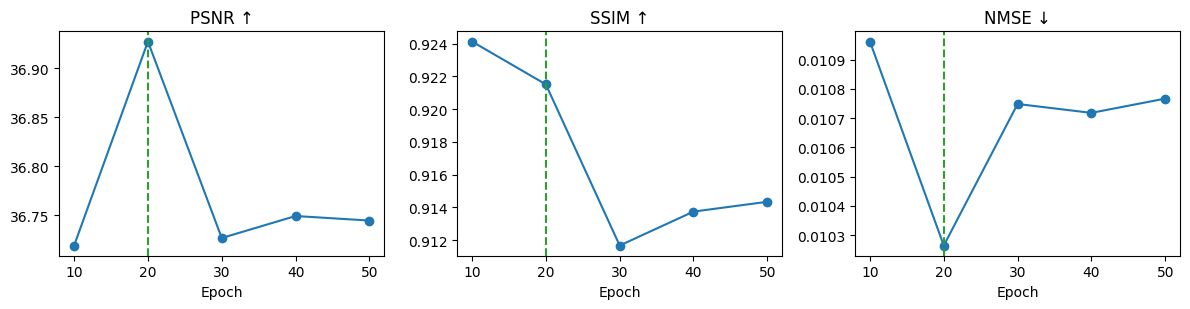

Epoch 20 selected by validation PSNR.


In [3]:
validation = [{'Epoch': row['completed_epochs'], 'Step': row['checkpoint_step'],
               'PSNR ↑': row['unrolled_rdbm']['psnr'], 'SSIM ↑': row['unrolled_rdbm']['ssim'],
               'NMSE ↓': row['unrolled_rdbm']['nmse'], 'Residual ↓': row['unrolled_rdbm']['measurement_residual']}
              for row in selection['candidates']]
show_table(validation, [(key, key) for key in validation[0]])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for axis, metric in zip(axes, ['PSNR ↑', 'SSIM ↑', 'NMSE ↓']):
    axis.plot([row['Epoch'] for row in validation], [row[metric] for row in validation], marker='o')
    axis.axvline(selection['completed_epochs'], color='tab:green', linestyle='--')
    axis.set(xlabel='Epoch', title=metric)
plt.tight_layout(); plt.show()
print(f"Epoch {selection['completed_epochs']} selected by validation PSNR.")

## Held-out test comparison

In [4]:
comparison = []
for name, values in [('Zero-filled', test['zero_filled']), ('RDBM', rdbm['rdbm']), ('Unrolled RDBM', test['unrolled_rdbm'])]:
    comparison.append({'Method': name, 'PSNR ↑': values['psnr'], 'SSIM ↑': values['ssim'],
                       'Complex NMSE ↓': values['nmse'], 'Residual ↓': values['measurement_residual'],
                       'Seconds/slice ↓': values.get('seconds_per_slice', np.nan)})
show_table(
    comparison,
    [(key, key) for key in comparison[0]],
    bold_best={'PSNR ↑': 'max', 'SSIM ↑': 'max', 'Complex NMSE ↓': 'min',
               'Residual ↓': 'min', 'Seconds/slice ↓': 'min'},
)
gain = test['unrolled_rdbm']['psnr'] - rdbm['rdbm']['psnr']
nmse_change = 100 * (1 - test['unrolled_rdbm']['nmse'] / rdbm['rdbm']['nmse'])
print(f'Unrolled vs RDBM: {gain:+.2f} dB PSNR and {nmse_change:.1f}% lower complex NMSE.')

Method,PSNR ↑,SSIM ↑,Complex NMSE ↓,Residual ↓,Seconds/slice ↓
Zero-filled,29.7164,0.8295,0.0714,0.1622,nan
RDBM,35.6007,0.9207,0.0559,0.1450,0.1916
Unrolled RDBM,36.3693,0.9088,0.0406,0.1487,0.0696


Unrolled vs RDBM: +0.77 dB PSNR and 27.4% lower complex NMSE.


## Representative reconstruction and cascade progression

The slice is selected automatically as the test case closest to the median unrolled
PSNR gain. Image and error scales are shared across columns.

Sample: file_brain_AXFLAIR_203_6000916:7


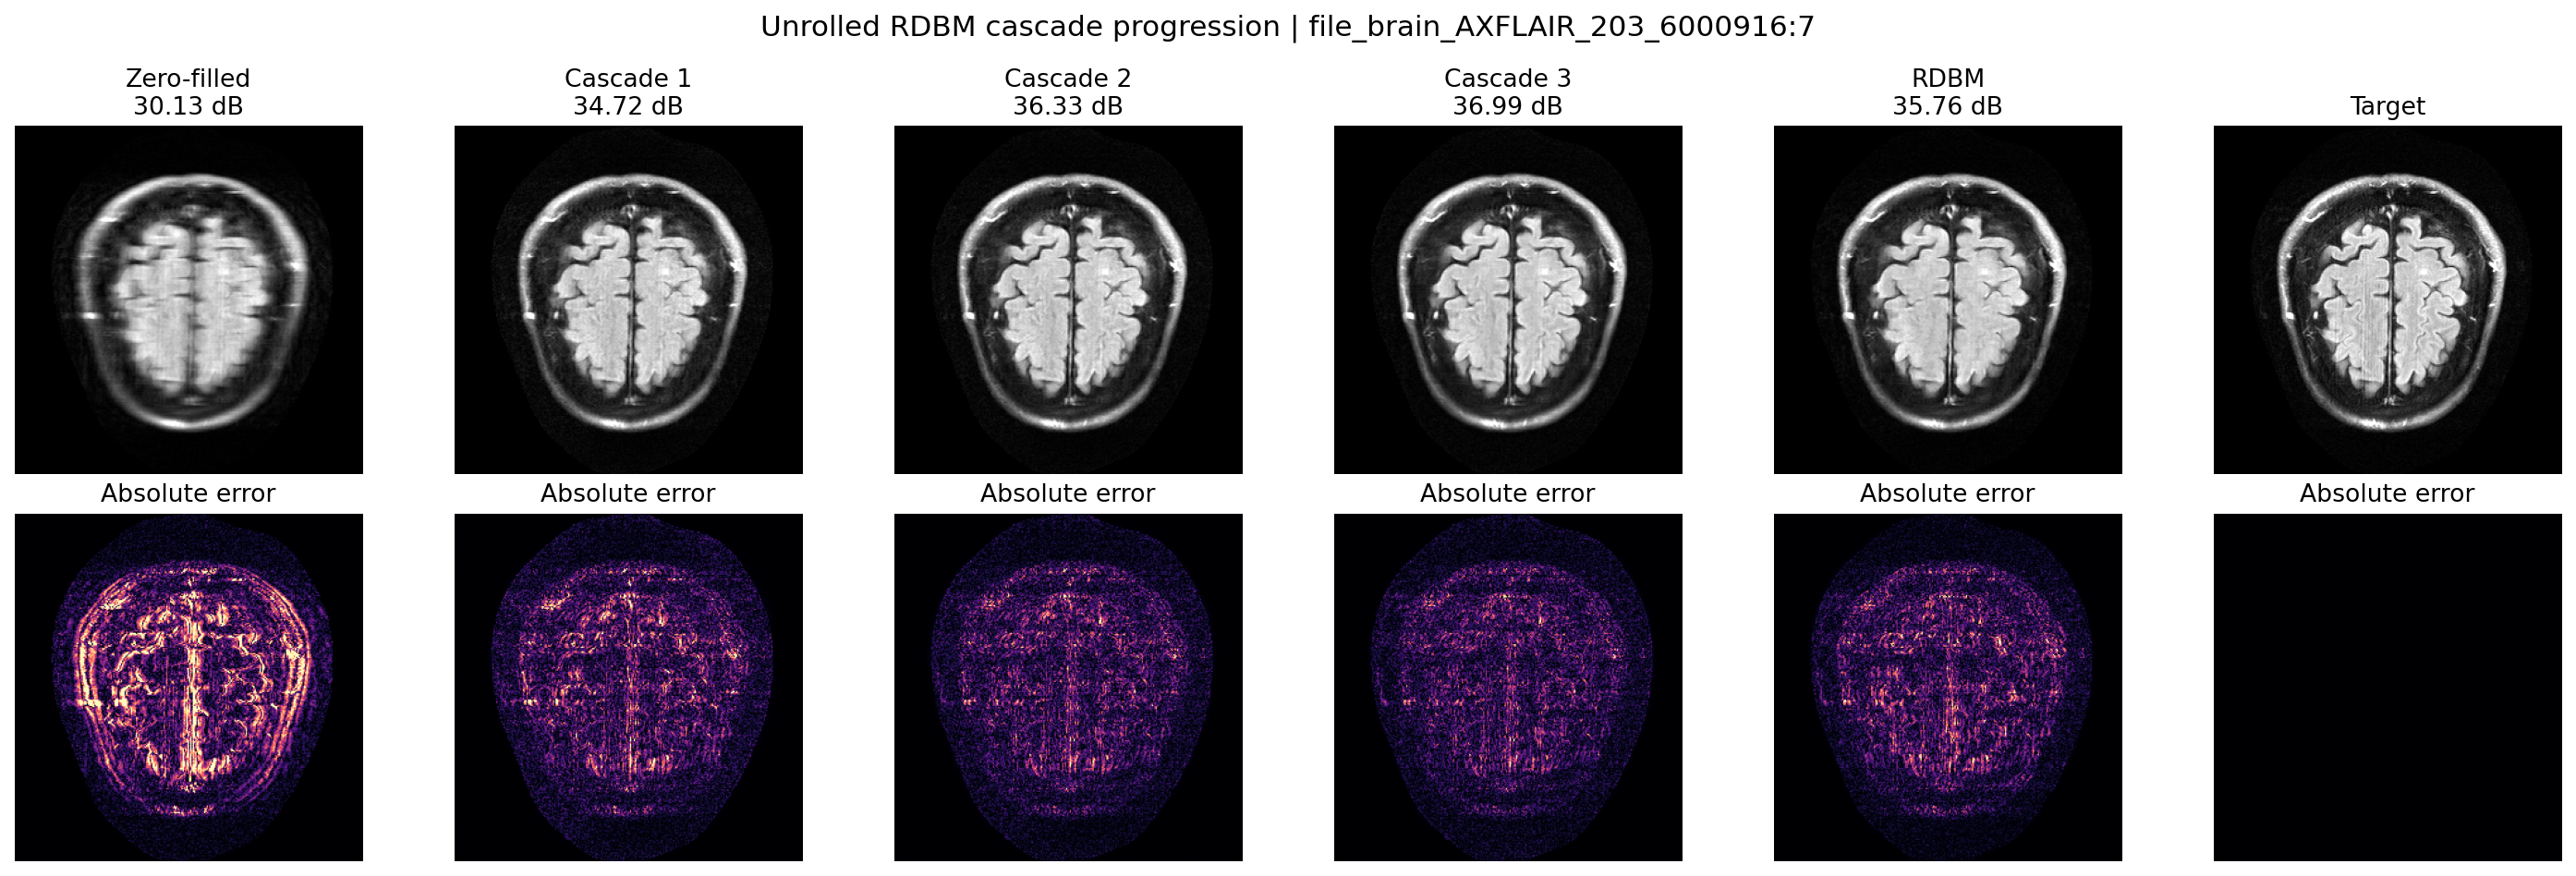

In [5]:
print(f"Sample: {figure_metadata['sample_id']}")
display(Image(filename=str(ROOT/'results/unrolled_rdbm_evaluation/qualitative/cascade_comparison.png'), width=2400))

\resumeItem{Engineered acoustic signal features to train machine learning models for medical device localization, achieving \textbf{0.841 ROC-AUC} in anatomical region classification.}